# **​# GSE183947: Breast Cancer Bulk RNA-Seq Transcriptomic Analysis**

This notebook presents an end-to-end, automated transcriptomic analysis pipeline for bulk RNA-Seq data from GEO Study GSE183947. The project investigates differential gene expression patterns in human breast cancer model samples under experimental treatment compared to untreated controls.

### **Dataset Specifications**
*   ​Dataset ID: GSE183947
*   ​Organism: Homo sapiens
*   ​Experimental Design: 6 total samples (3 Control vs. 3 Treated)
*   ​Data Input: Un-normalized gene count matrix generated via HISAT2 alignment and `featureCounts` / `Column Join` processing on Galaxy Europe.

### **Analytical Pipeline Workflow**
1. **​Cloud Environment Setup:** Persistent package storage configuration and runtime patch initialization.
2. **Automated Data Ingestion:** Programmatic retrieval of count matrices from Galaxy Europe via REST API (bioblend).
3. **​Statistical Modeling:** Negative binomial generalized linear model fitting, size-factor estimation, dispersion shrinkage, and Wald testing via PyDESeq2.
4. **Gene Annotation:** Entrez ID conversion to HGNC official gene symbols using the MyGene API (mygene).
5. **Exploratory Visualization:** Publication-ready Volcano Plots, Expression Clustered Heatmaps, and Gene Ontology (GO) Biological Process pathway enrichment (gseapy).
6. **Asset Archiving:** Automatic backup of normalized tables and high-resolution vector figures directly to Google Drive.





## **Environment Configuration, Library Imports & Compatibility Patching**
This cell configures the runtime environment by linking pre-installed multi-omics packages from a persistent Google Drive directory (bioinfo). It applies a runtime compatibility patch for Pandas 3.0 / anndata string initialization and loads all analytical and graphic libraries required for downstream processing.

In [ ]:
import os
import sys
import shutil
from google.colab import drive

# 1. Mount Google Drive and link bioinfo environment
drive.mount('/content/drive')
bioinfo_path = '/content/drive/MyDrive/Colab_Environment/bioinfo'
if bioinfo_path not in sys.path:
    sys.path.append(bioinfo_path)

# 2. Apply Pandas 3.0 / AnnData compatibility patch safely (non-recursive)
import pandas as pd
if not hasattr(pd.StringDtype, '_orig_init'):
    pd.StringDtype._orig_init = pd.StringDtype.__init__
    def _patched_init(self, *args, **kwargs):
        kwargs.pop('na_value', None)
        return pd.StringDtype._orig_init(self, *args, **kwargs)
    pd.StringDtype.__init__ = _patched_init

# 3. Load all core analysis & visualization libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from adjustText import adjust_text
import mygene
import gseapy as gp
from bioblend.galaxy import GalaxyInstance
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

print("✅ All imports, Google Drive links, and compatibility patches loaded successfully!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ All imports, Google Drive links, and compatibility patches loaded successfully!


## **Automated Dataset Retrieval from Galaxy Europe**
Connects programmatically to the Galaxy Europe instance using `bioblend` REST API integration. It queries active account histories, identifies the concatenated `Column Join` count matrix generated during upstream alignment and quantification, and streams it directly into the Colab execution environment as `counts_matrix.tsv`.

In [ ]:
# Connect to Galaxy Europe API
GALAXY_URL = 'https://usegalaxy.eu/'
API_KEY = 'YOUR GALAXY API KEY'

gi = GalaxyInstance(url=GALAXY_URL, key=API_KEY)
histories = gi.histories.get_histories()

target_dataset_id = None
target_history_name = ""

# Search histories for the combined count matrix
for h in histories:
    h_id = h['id']
    h_name = h['name']
    datasets = gi.histories.show_history(h_id, contents=True)
    valid_datasets = [
        d for d in datasets
        if d.get('history_content_type') == 'dataset' and d.get('state') == 'ok'
    ]
    if not valid_datasets:
        continue
    for d in valid_datasets:
        d_name = d['name']
        name_lower = d_name.lower()
        if any(k in name_lower for k in ['column join', 'join', 'counts', 'matrix', 'featurecounts', 'tabular']):
            target_dataset_id = d['id']
            target_history_name = h_name

# Download target dataset
if target_dataset_id:
    print(f"🎯 Found Target Dataset ID [{target_dataset_id}] in history '{target_history_name}'")
    gi.datasets.download_dataset(
        target_dataset_id,
        file_path='counts_matrix.tsv',
        use_default_filename=False
    )
    print("✅ Download Complete! 'counts_matrix.tsv' is ready for downstream analysis.")
else:
    print("⚠️ Target dataset not automatically identified. Verify dataset names in Galaxy.")


## **PyDESeq2 Differential Expression Analysis & Annotation**
​
Initializes the `DeseqDataSet` object, defines experimental conditions (3 Control vs. 3 Treated), and executes full differential expression modeling via `PyDESeq2`. Following Wald statistical testing, Entrez gene identifiers are query-mapped to official HGNC symbols via `mygene`, and loci are classified by strict significance thresholds (*adj. p* < 0.05, Log₂FC > 1.0).

In [ ]:
# Load count matrix
counts = pd.read_csv('counts_matrix.tsv', sep='\t', index_col=0)
counts.columns = [c.split('/')[-1].replace('.bam', '').strip() for c in counts.columns]

# Transpose matrix for PyDESeq2 (samples as rows, genes as columns)
counts_transposed = counts.T
counts_transposed.index = counts_transposed.index.astype(str)
counts_transposed.columns = counts_transposed.columns.astype(str)

# Define experiment design (3 Control vs 3 Treated)
conditions = ['Control', 'Control', 'Control', 'Treated', 'Treated', 'Treated']
metadata = pd.DataFrame({'condition': conditions}, index=counts_transposed.index)

print("🧬 Executing PyDESeq2 Differential Expression Analysis...")
dds = DeseqDataSet(
    counts=counts_transposed,
    metadata=metadata,
    design_factors="condition",
    ref_level=["condition", "Control"]
)
dds.deseq2()

# Compute Wald test statistics
stat_res = DeseqStats(dds, contrast=["condition", "Treated", "Control"])
stat_res.summary()
res_df = stat_res.results_df

# Map Entrez IDs to HGNC symbols
print("🏷️ Mapping Entrez Gene IDs to HGNC Symbols...")
mg = mygene.MyGeneInfo()
entrez_ids = res_df.index.astype(str).tolist()
gene_info = mg.querymany(entrez_ids, scopes='entrezgene', fields='symbol', species='human', as_dataframe=True)

if 'symbol' in gene_info.columns:
    clean_info = gene_info[~gene_info.index.duplicated(keep='first')]
    gene_dict = dict(zip(clean_info.index.astype(str), clean_info['symbol'].astype(str)))
    symbols = []
    for idx in res_df.index.astype(str):
        sym = gene_dict.get(idx, idx)
        symbols.append(sym if pd.notna(sym) and sym != 'nan' else idx)
    res_df['symbol'] = symbols
else:
    res_df['symbol'] = res_df.index.astype(str)

# Categorize DEGs by significance thresholds
res_df['significance'] = 'Not Significant'
res_df.loc[(res_df['padj'] < 0.05) & (res_df['log2FoldChange'] > 1.0), 'significance'] = 'Upregulated'
res_df.loc[(res_df['padj'] < 0.05) & (res_df['log2FoldChange'] < -1.0), 'significance'] = 'Downregulated'

# Export output CSV
res_df.to_csv('GSE183947_DESeq2_results.csv')

print("\n✅ PyDESeq2 Analysis Complete!")
print(f"Total Genes Evaluated: {len(res_df)}")
print(f"Upregulated DEGs: {(res_df['significance'] == 'Upregulated').sum()}")
print(f"Downregulated DEGs: {(res_df['significance'] == 'Downregulated').sum()}")


🧬 Executing PyDESeq2 Differential Expression Analysis...
Using None as control genes, passed at DeseqDataSet initialization


/tmp/ipykernel_2308/1469338680.py:15: DeprecationWarning: ref_level is deprecated and no longer has any effect. It will beremoved in a future release.
  dds = DeseqDataSet(
/tmp/ipykernel_2308/1469338680.py:15: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds = DeseqDataSet(
Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 32.19 seconds.

Fitting dispersion trend curve...
... done in 0.78 seconds.

Fitting MAP dispersions...
... done in 41.37 seconds.

Fitting LFCs...
... done in 24.46 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 9.57 seconds.

INFO:biothings.client:querying 1-1000 ...


Log2 fold change & Wald test p-value: condition Treated vs Control
           baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
Geneid                                                                     
1        179.360535        0.164193  0.351276  0.467419  0.640200  0.999892
10         1.818128       -0.206069  1.709619 -0.120535  0.904059       NaN
100      444.428282       -1.025276  0.529238 -1.937268  0.052713  0.513892
1000    2168.763610        3.367347  0.749781  4.491109  0.000007  0.000877
10000    146.316253        0.431080  0.930477  0.463289  0.643157  0.999892
...             ...             ...       ...       ...       ...       ...
9991     883.945121        0.131023  0.397367  0.329728  0.741605  0.999892
9992       3.070713        0.888070  1.417156  0.626657  0.530884       NaN
9993    2316.357532       -0.236791  0.398643 -0.593994  0.552516  0.999892
9994     429.056187        0.116534  0.414266  0.281302  0.778479  0.999892
9997      12.568625  

INFO:biothings.client:querying 1001-2000 ...
INFO:biothings.client:querying 2001-3000 ...
INFO:biothings.client:querying 3001-4000 ...
INFO:biothings.client:querying 4001-5000 ...
INFO:biothings.client:querying 5001-6000 ...
INFO:biothings.client:querying 6001-7000 ...
INFO:biothings.client:querying 7001-8000 ...
INFO:biothings.client:querying 8001-9000 ...
INFO:biothings.client:querying 9001-10000 ...
INFO:biothings.client:querying 10001-11000 ...
INFO:biothings.client:querying 11001-12000 ...
INFO:biothings.client:querying 12001-13000 ...
INFO:biothings.client:querying 13001-14000 ...
INFO:biothings.client:querying 14001-15000 ...
INFO:biothings.client:querying 15001-16000 ...
INFO:biothings.client:querying 16001-17000 ...
INFO:biothings.client:querying 17001-18000 ...
INFO:biothings.client:querying 18001-19000 ...
INFO:biothings.client:querying 19001-20000 ...
INFO:biothings.client:querying 20001-21000 ...
INFO:biothings.client:querying 21001-22000 ...
INFO:biothings.client:querying


✅ PyDESeq2 Analysis Complete!
Total Genes Evaluated: 28395
Upregulated DEGs: 212
Downregulated DEGs: 156


## **Differential Expression Visualization: Volcano Plot**
​
Constructs a publication-grade Volcano Plot contrasting statistical confidence (-log₁₀ *adj. p*) against effect magnitude (Log₂FC). Significant upregulated and downregulated genes are highlighted in distinct colorways, with top-ranking DEGs dynamically annotated using `adjustText` to eliminate overlapping labels.

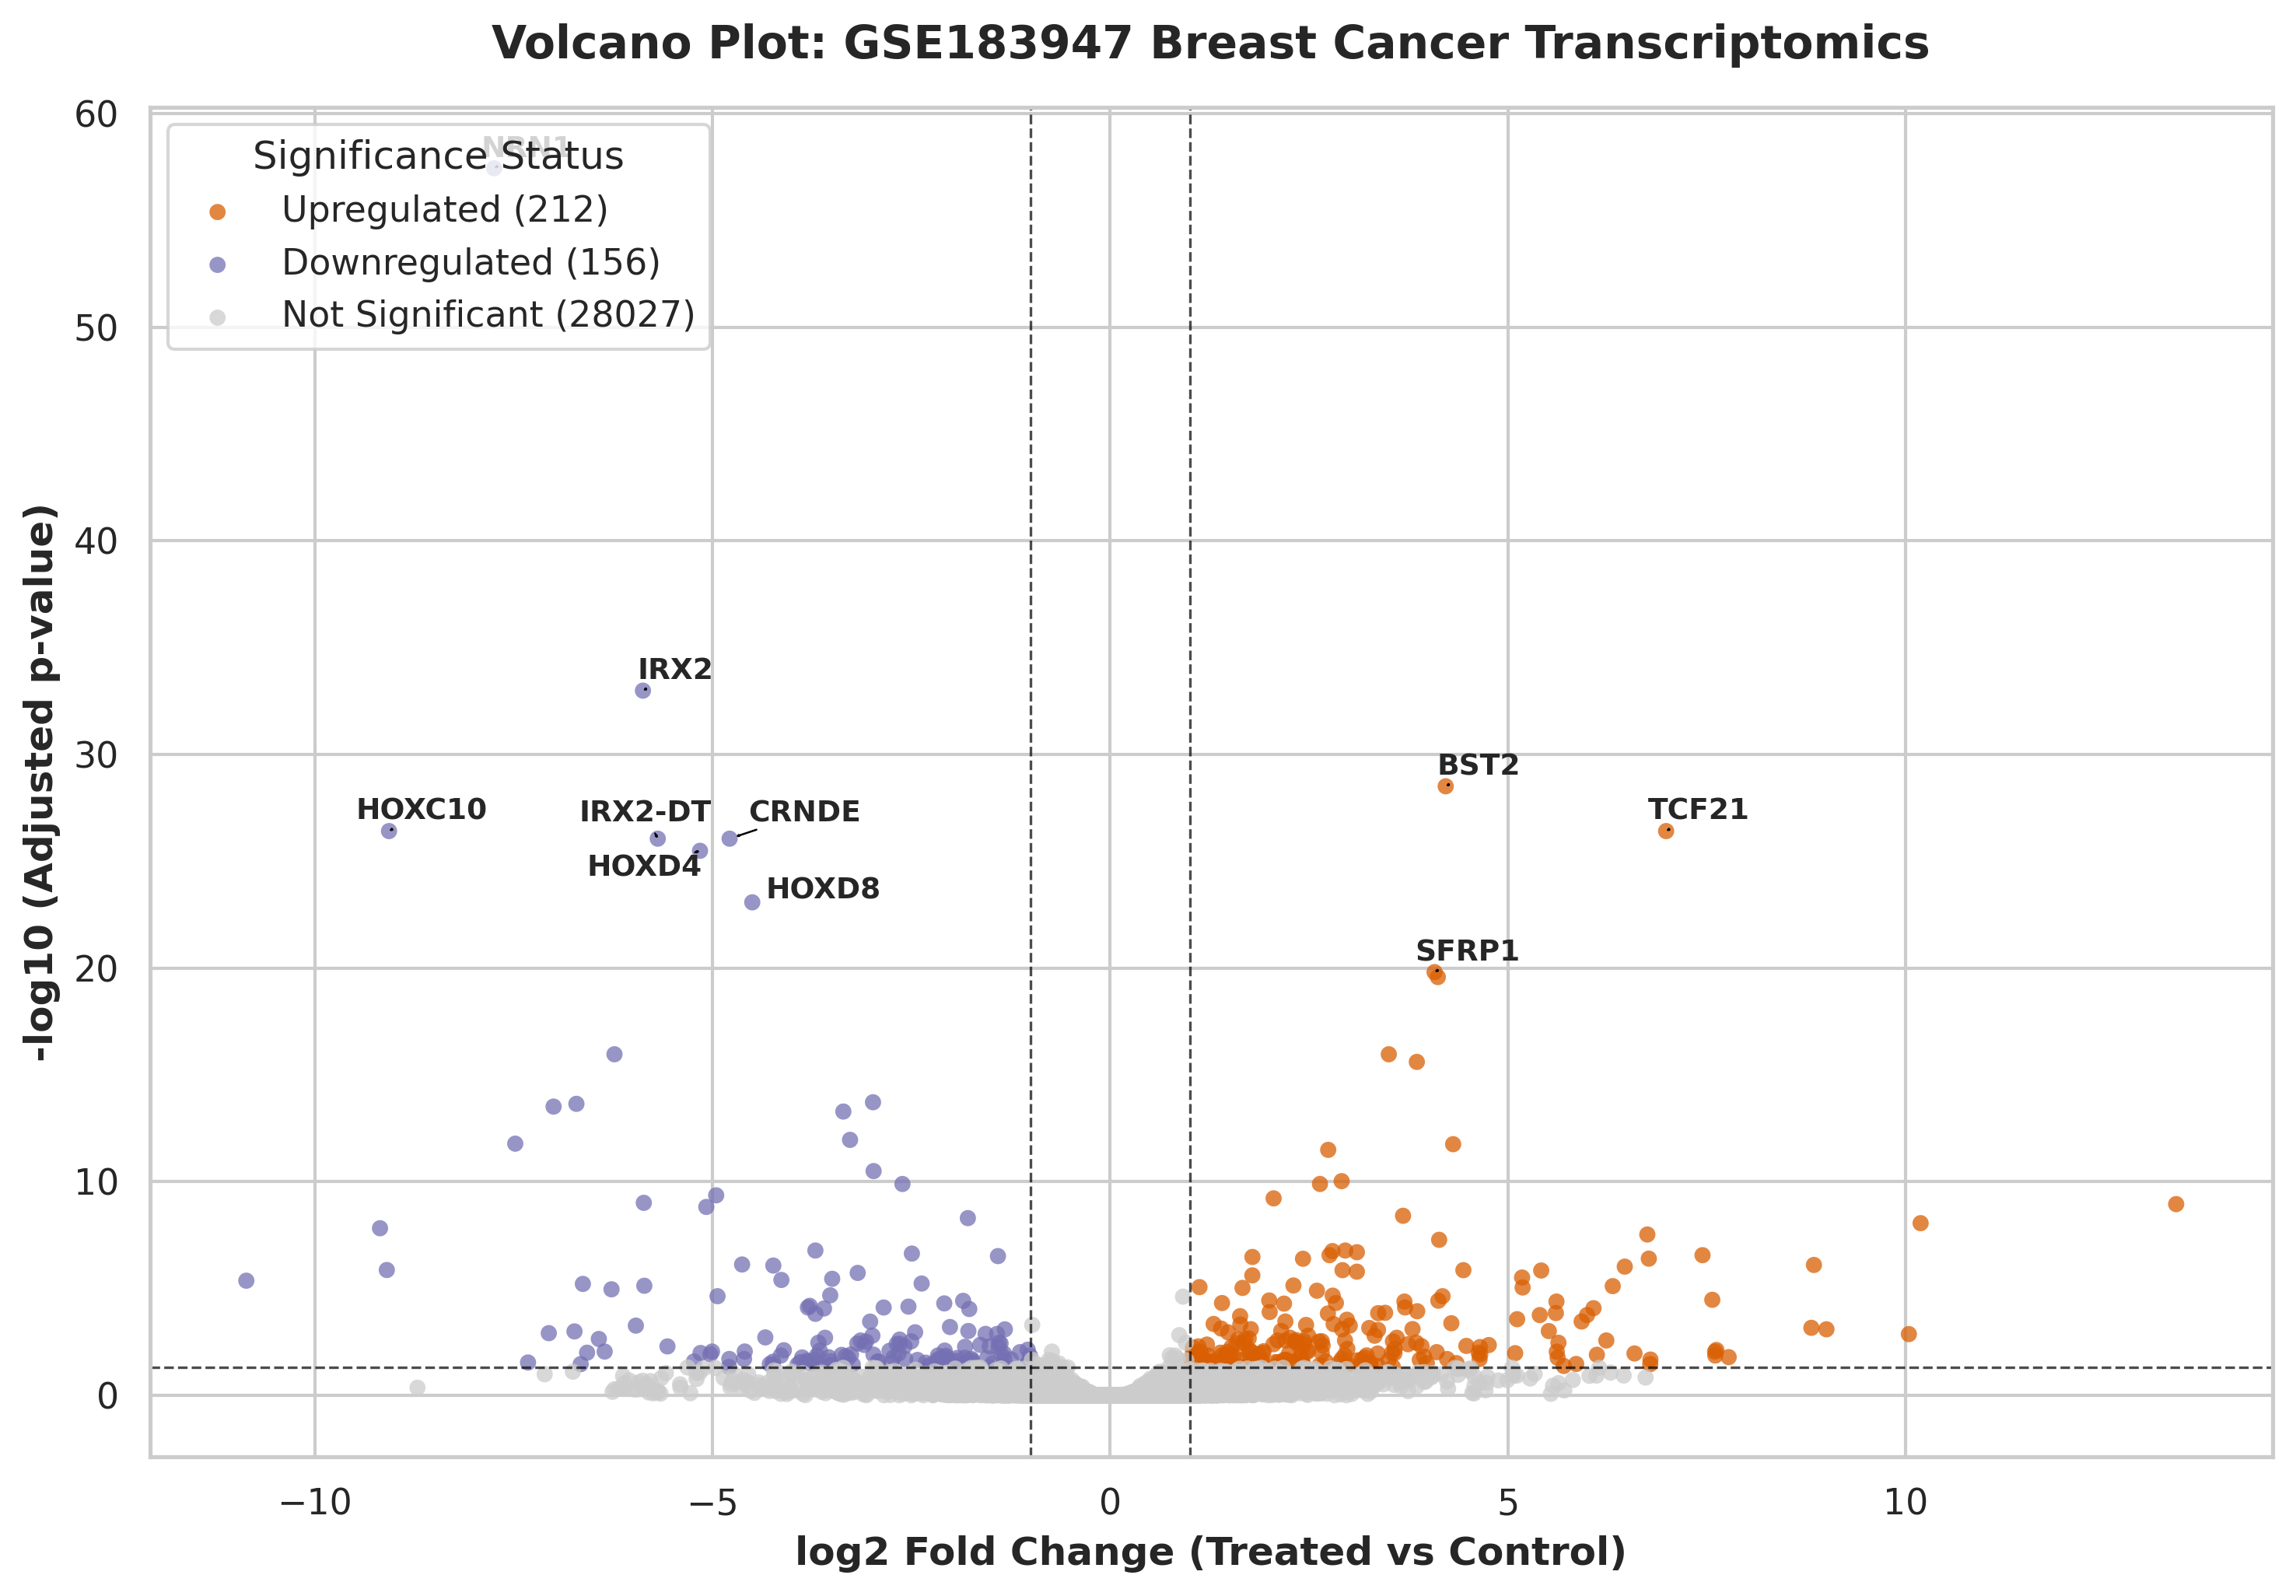

✅ Volcano plot saved as 'GSE183947_Volcano_Plot.png'


In [ ]:
# Calculate -log10(padj)
res_df['neg_log10_padj'] = -np.log10(res_df['padj'].replace(0, 1e-300))

# Figure styling
plt.figure(figsize=(10, 7), dpi=300)
sns.set_theme(style='whitegrid', font='sans-serif')

color_dict = {
    'Upregulated': '#d95f02',
    'Downregulated': '#7570b3',
    'Not Significant': '#cccccc'
}

for category, color in color_dict.items():
    subset = res_df[res_df['significance'] == category]
    plt.scatter(
        subset['log2FoldChange'],
        subset['neg_log10_padj'],
        c=color,
        label=f"{category} ({len(subset)})",
        alpha=0.75,
        edgecolors='none',
        s=25
    )

# Cutoff threshold lines
plt.axvline(x=1.0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
plt.axvline(x=-1.0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
plt.axhline(y=-np.log10(0.05), color='black', linestyle='--', linewidth=0.8, alpha=0.7)

# Annotate top 10 DEGs
top_degs = res_df[res_df['significance'] != 'Not Significant'].sort_values('padj').head(10)
texts = []
for _, row in top_degs.iterrows():
    texts.append(
        plt.text(
            row['log2FoldChange'],
            row['neg_log10_padj'],
            str(row['symbol']),
            fontsize=9,
            fontweight='bold',
            ha='center',
            va='bottom'
        )
    )

adjust_text(texts, arrowprops=dict(arrowstyle='->', color='black', lw=0.6))

plt.title('Volcano Plot: GSE183947 Breast Cancer Transcriptomics', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('log2 Fold Change (Treated vs Control)', fontsize=12, fontweight='bold')
plt.ylabel('-log10 (Adjusted p-value)', fontsize=12, fontweight='bold')
plt.legend(title='Significance Status', frameon=True, loc='upper left')

plt.tight_layout()
plt.savefig('GSE183947_Volcano_Plot.png', dpi=300)
plt.show()

print("✅ Volcano plot saved as 'GSE183947_Volcano_Plot.png'")

## **Functional Pathway & Gene Ontology (GO) Enrichment Analysis**
Isolates significant DEGs and submits them to the Enrichr API via `gseapy` to evaluate over-represented biological pathways. Results are queried against the **GO Biological Process 2023** database and visualized as a horizontal bar plot ranking top enriched mechanisms.

In [ ]:
# Isolate significant DEG symbols
sig_degs = res_df[res_df['significance'] != 'Not Significant']['symbol'].dropna().astype(str).tolist()
sig_degs = [g for g in sig_degs if g != 'nan']

print(f"🧬 Querying Enrichr API with {len(sig_degs)} DEGs...")

# Perform Gene Ontology Enrichment
enr = gp.enrichr(
    gene_list=sig_degs,
    gene_sets=['GO_Biological_Process_2023'],
    organism='homo sapiens',
    outdir=None
)

# Plot top enriched pathways
ax = gp.barplot(
    enr.res2d,
    title='Top GO Biological Processes Enriched in DEGs',
    top_term=10,
    color='#2b5c8f',
    figsize=(8, 6),
    ofname='GSE183947_GO_Enrichment.png'
)

plt.show()

print("✅ GO Enrichment plot saved as 'GSE183947_GO_Enrichment.png'")


🧬 Querying Enrichr API with 368 DEGs...
✅ GO Enrichment plot saved as 'GSE183947_GO_Enrichment.png'


## **Expression Clustering & Heatmap Generation**
Subsets the top 30 most significant differentially expressed genes, computes row-wise Z-score standardizations across log-transformed Counts Per Million (log₂CPM + 1), and generates a hierarchically clustered heatmap (`seaborn.clustermap`) displaying gene co-expression modules across experimental groups.

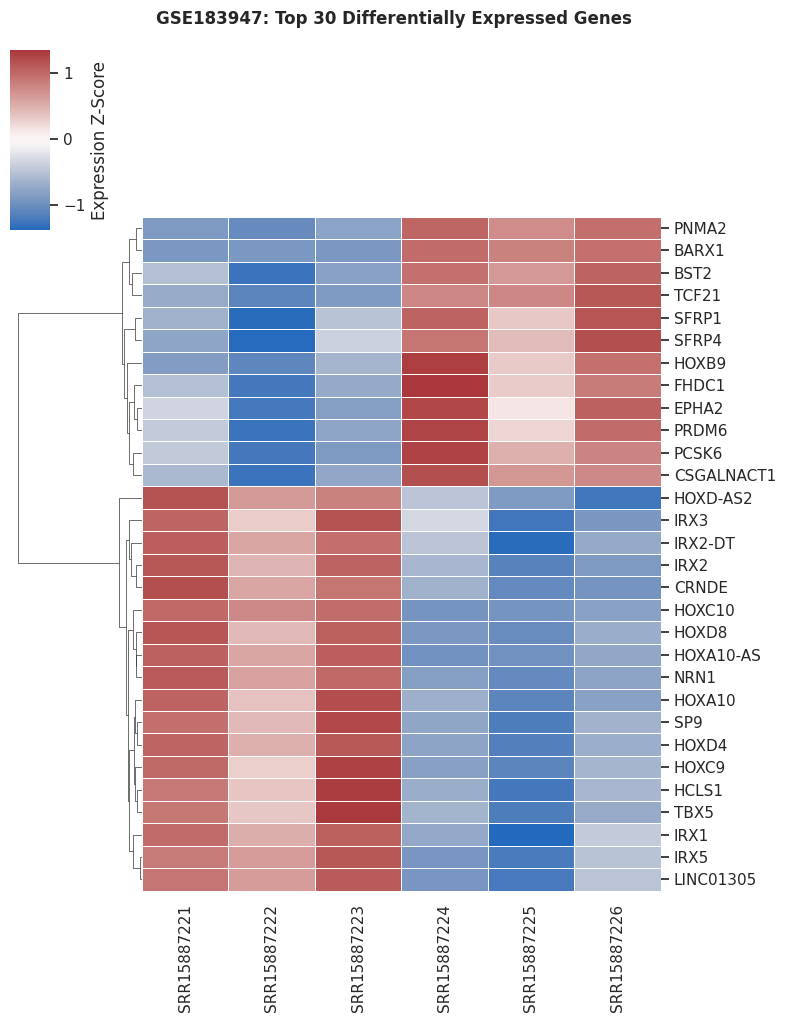

✅ Heatmap saved as 'GSE183947_Heatmap.png'


In [ ]:
# Select top 30 significant DEGs
top_30_ids = res_df[res_df['significance'] != 'Not Significant'].sort_values('padj').head(30).index.astype(str)

# Extract counts and compute log2(CPM + 1)
cpm = counts.loc[counts.index.astype(str).isin(top_30_ids)] + 1
log_cpm = np.log2(cpm)

# Replace Entrez IDs with HGNC gene symbols
symbol_map = dict(zip(res_df.index.astype(str), res_df['symbol']))
log_cpm.index = [symbol_map.get(idx, idx) for idx in log_cpm.index.astype(str)]

# Standardize Z-scores per gene row
z_scores = log_cpm.apply(lambda x: (x - x.mean()) / x.std(), axis=1)

# Render Clustered Heatmap
sns.set_theme(style='white')
g = sns.clustermap(
    z_scores,
    cmap='vlag',
    col_cluster=False,
    row_cluster=True,
    linewidths=0.4,
    figsize=(8, 10),
    cbar_kws={'label': 'Expression Z-Score'}
)

g.fig.suptitle('GSE183947: Top 30 Differentially Expressed Genes', y=1.02, fontsize=12, fontweight='bold')
plt.savefig('GSE183947_Heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Heatmap saved as 'GSE183947_Heatmap.png'")


## **Automated Project Asset Archiving**
Ensures complete reproducibility and data persistence by creating a dedicated project directory in Google Drive (`GSE183947_BreastCancer_Project`) and copying all resulting count matrices, statistical tables, and high-resolution figures into cloud storage.

In [ ]:
project_drive_dir = '/content/drive/MyDrive/GSE183947_BreastCancer_Project'
os.makedirs(project_drive_dir, exist_ok=True)

files_to_save = [
    'counts_matrix.tsv',
    'GSE183947_DESeq2_results.csv',
    'GSE183947_Volcano_Plot.png',
    'GSE183947_GO_Enrichment.png',
    'GSE183947_Heatmap.png'
]

print(f"📁 Archiving files to: {project_drive_dir}\n")
for file in files_to_save:
    if os.path.exists(file):
        shutil.copy(file, os.path.join(project_drive_dir, file))
        print(f" - Saved: {file}")

print("\n🎉 Pipeline Execution Complete! All project assets are backed up to Drive.")

📁 Archiving files to: /content/drive/MyDrive/GSE183947_BreastCancer_Project

 - Saved: counts_matrix.tsv
 - Saved: GSE183947_DESeq2_results.csv
 - Saved: GSE183947_Volcano_Plot.png
 - Saved: GSE183947_GO_Enrichment.png
 - Saved: GSE183947_Heatmap.png

🎉 Pipeline Execution Complete! All project assets are backed up to Drive.


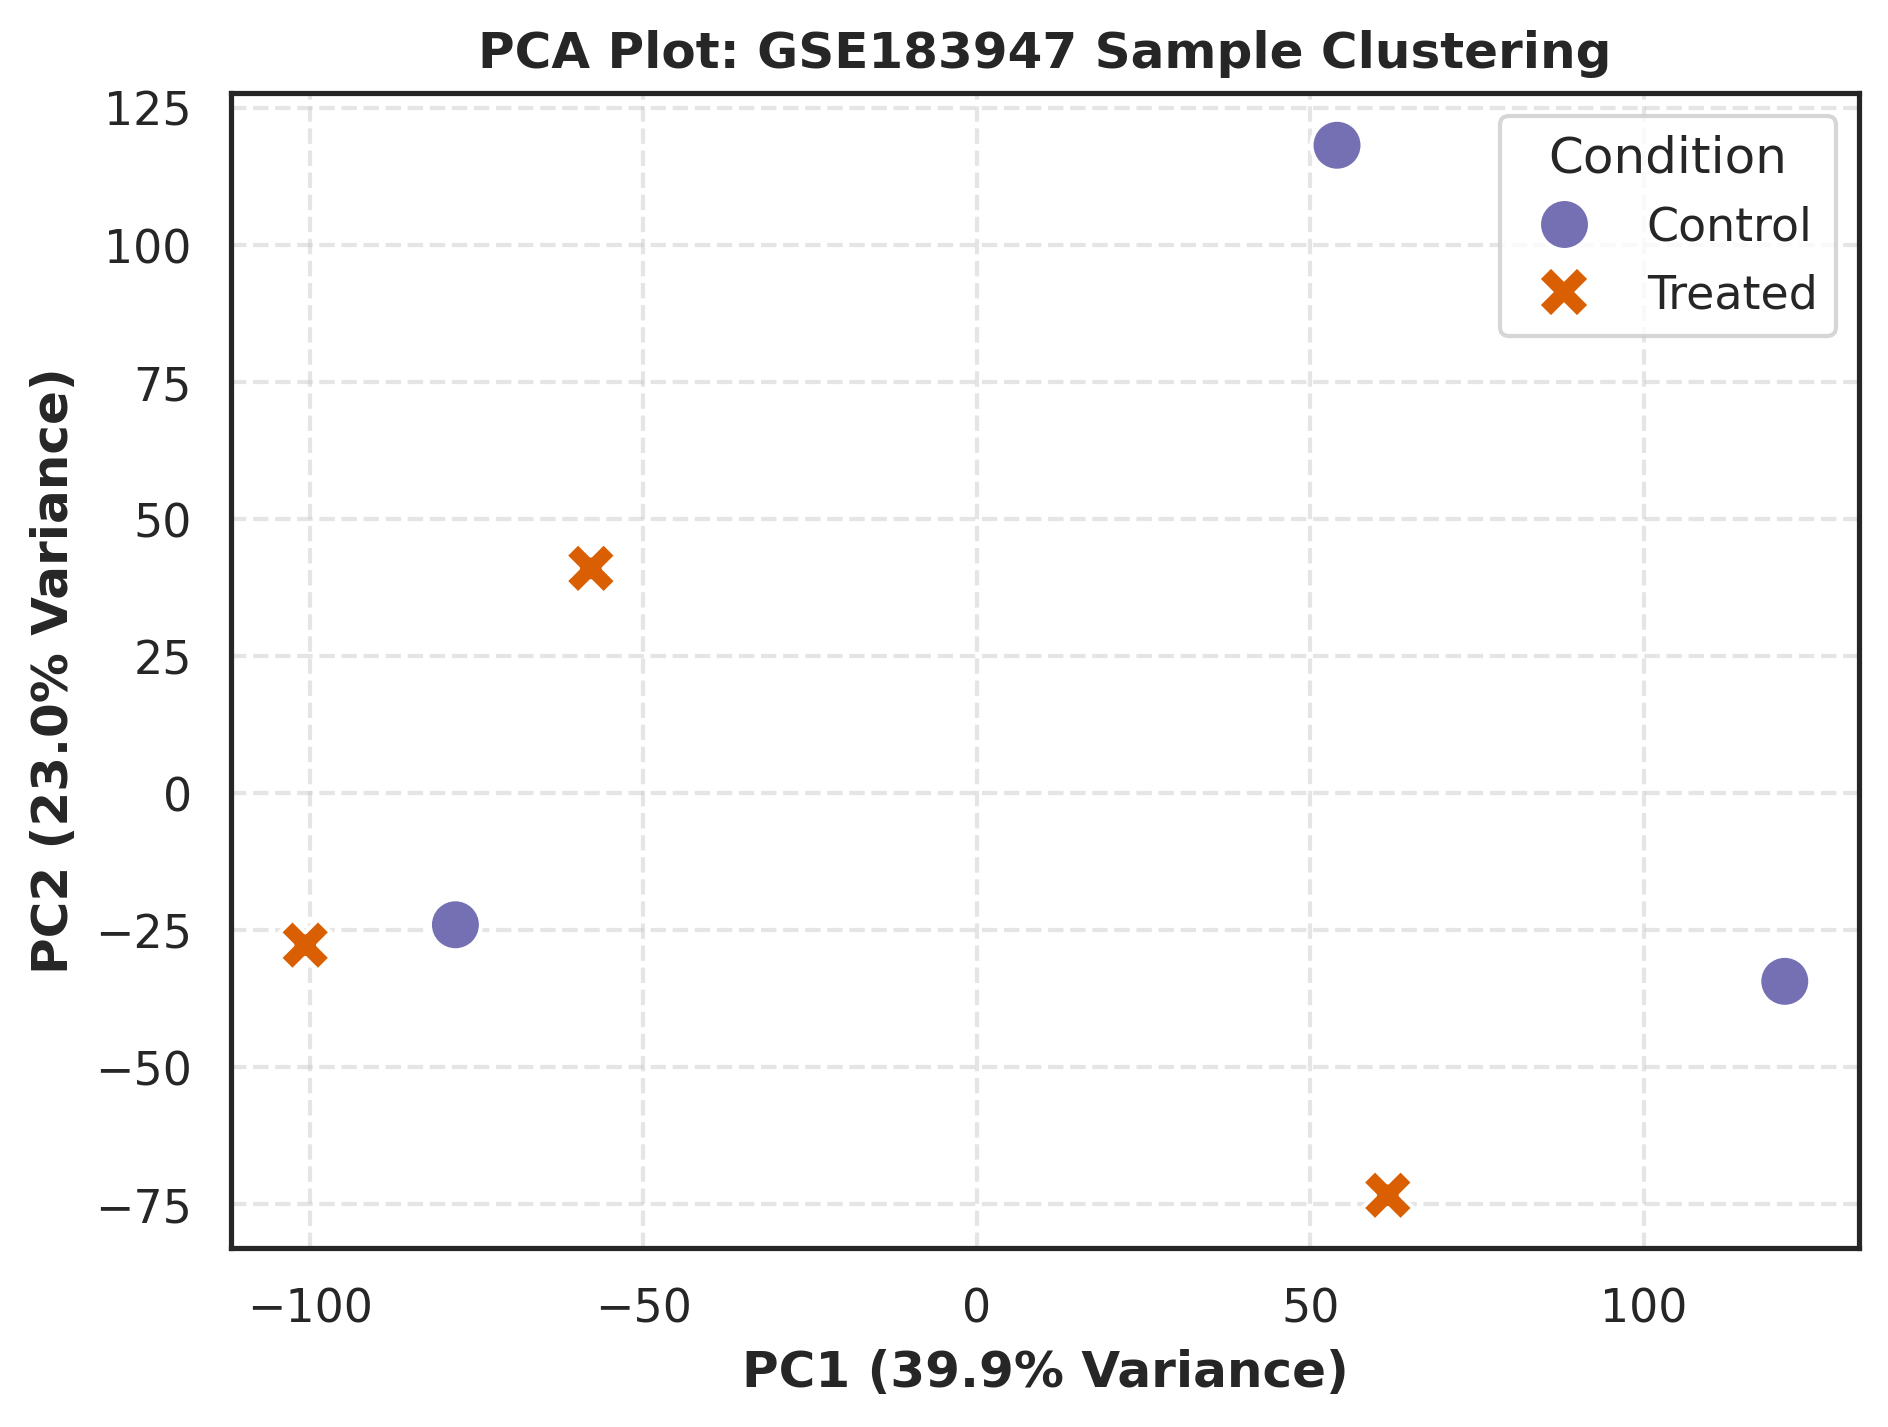

✅ PCA Plot saved as 'GSE183947_PCA_Plot.png'


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from pydeseq2.preprocessing import deseq2_norm

# 1. Compute Log2 transformed normalized counts
normalized_counts, _ = deseq2_norm(counts_transposed)
log_counts = np.log2(normalized_counts + 1)

# 2. Compute Principal Components (PC1 & PC2)
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca_res = pca.fit_transform(log_counts)

# Build DataFrame
pca_df = pd.DataFrame(pca_res, columns=['PC1', 'PC2'], index=log_counts.index)
pca_df['Condition'] = metadata['condition']

# 3. Render PCA Scatter Plot
plt.figure(figsize=(7, 5), dpi=300)
sns.scatterplot(
    data=pca_df, x='PC1', y='PC2', hue='Condition',
    style='Condition', s=150, palette={'Control': '#7570b3', 'Treated': '#d95f02'}
)

plt.title('PCA Plot: GSE183947 Sample Clustering', fontsize=12, fontweight='bold')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)', fontweight='bold')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)', fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)

plt.savefig('GSE183947_PCA_Plot.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ PCA Plot saved as 'GSE183947_PCA_Plot.png'")